In [1]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/src/exploration/../../../../models/hgm.py'>

In [3]:
gcamp = True
read_ids_gcamp = list(range(0, 33+1))
# read_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
# read_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [2, 4, 6]
	# read_ids_gfp = [2]
	plot_id_gfp = 2

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_datas(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_datas(path, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

In [5]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx_gcamp = file_ids_gcamp.index(plot_id_gcamp)
plot_idx_gfp = file_ids_gfp.index(plot_id_gfp)

selection_n = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]
selection_n_gcamp = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]
if gfp:
	selection_n_gfp = [label for label in selection_n if label in traces_gfp[plot_idx_gfp].columns]
# discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

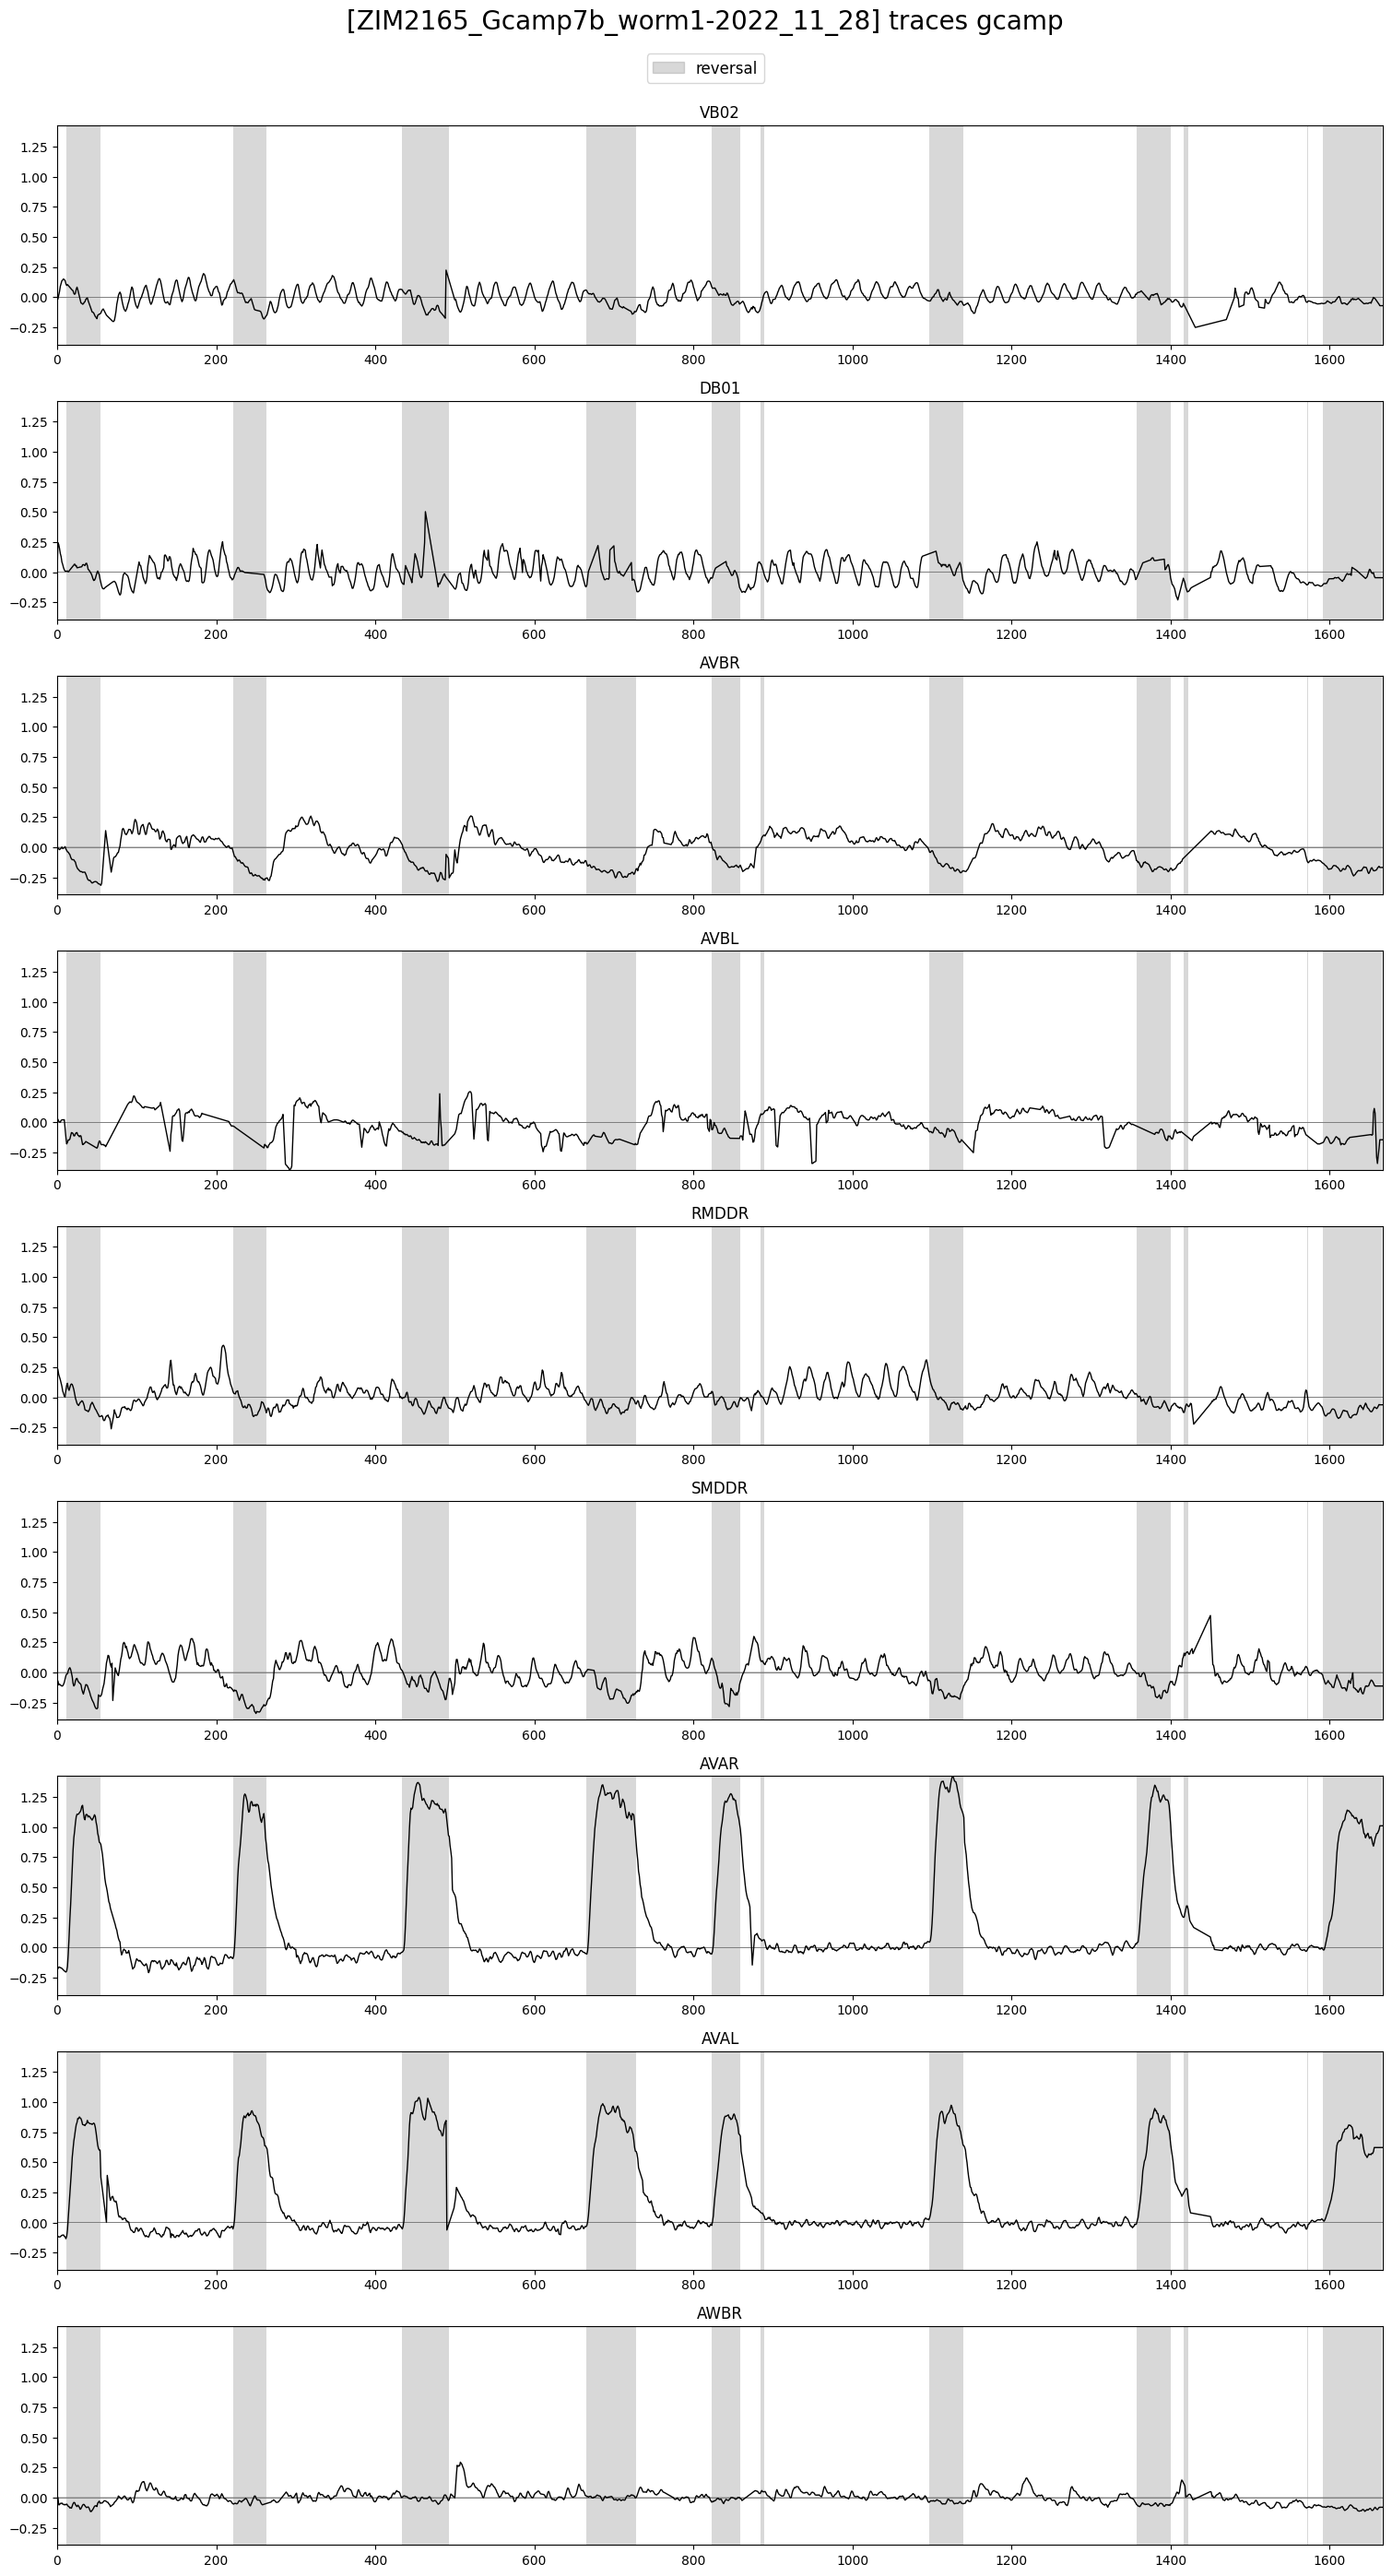

In [6]:
plot_utils.plot_traces(traces_gcamp[plot_idx_gcamp][selection_n_gcamp],
					   discrete_states_gcamp[plot_idx_gcamp][['REV']],
					   label='reversal',
					   title=f'[{filenames_gcamp[plot_idx_gcamp]}] traces gcamp', ylimits=None, plots_per_row=1)

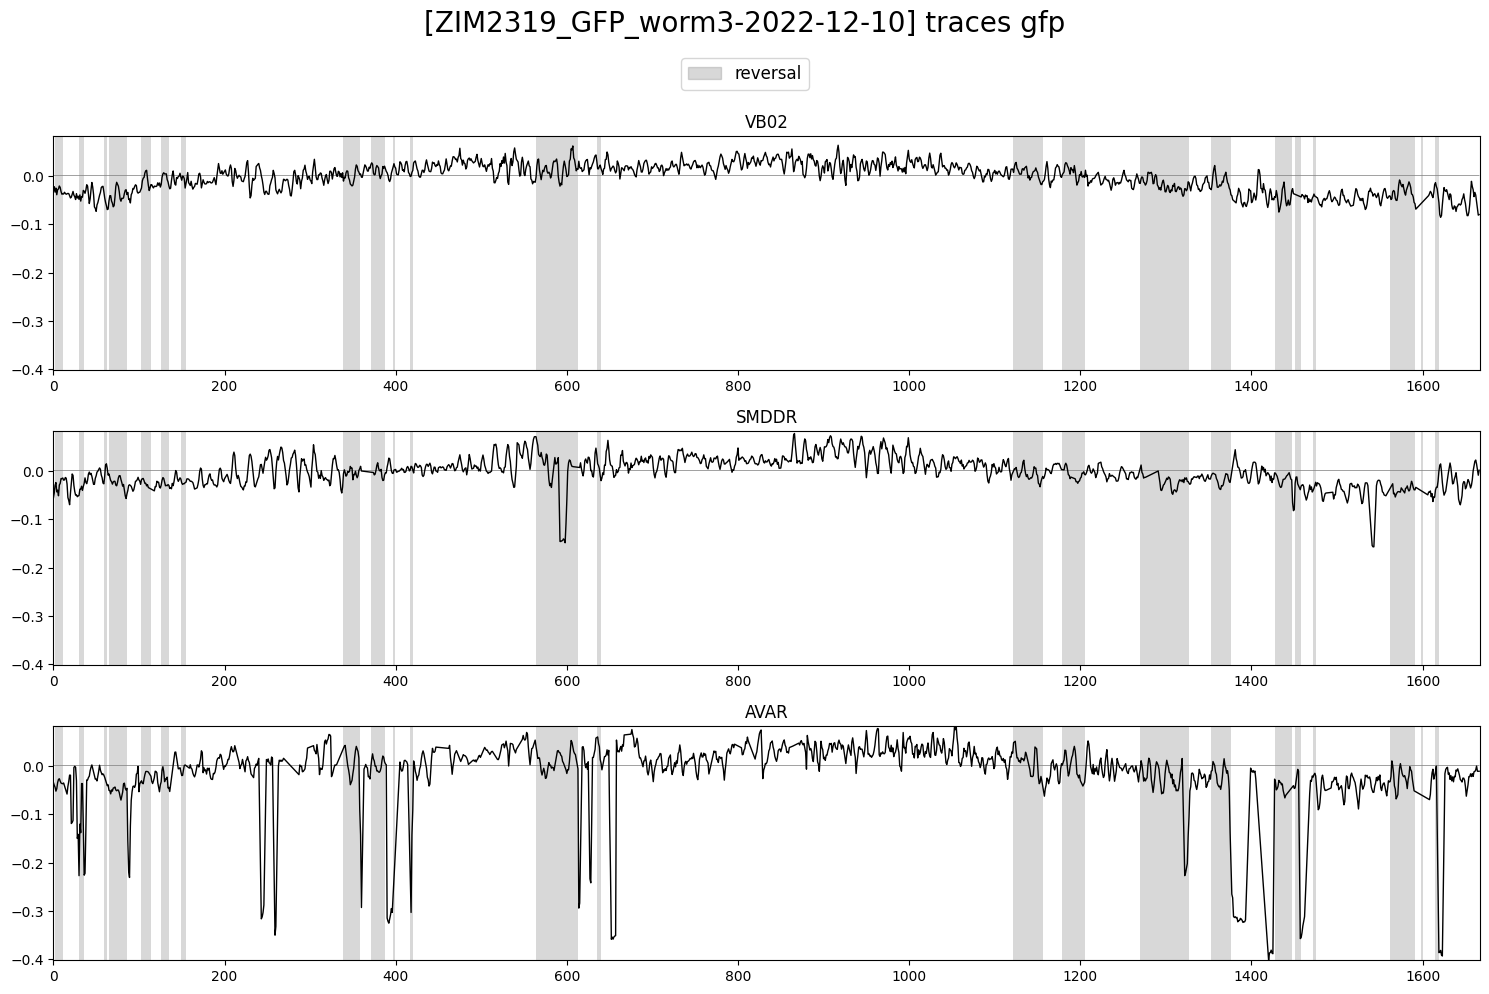

In [7]:
plot_utils.plot_traces(traces_gfp[plot_idx_gfp][selection_n_gfp],
					   discrete_states_gfp[plot_idx_gfp][['REV']],
					   label='reversal',
					   title=f'[{filenames_gfp[plot_idx_gfp]}] traces gfp', ylimits=None, plots_per_row=1)

In [10]:
for i, trace in enumerate(traces_gcamp):
	print(np.median(trace.values, axis=0))

[-9.93001236e-05  1.37144281e-03  6.16987639e-04  2.84591875e-04
 -2.82137729e-05  1.15324792e-04 -7.67018059e-04  3.16782168e-03
 -6.23423891e-03 -1.97607395e-04 -4.61922136e-03  3.30558141e-03
 -2.64552472e-03  1.56066890e-03  4.00693765e-03  2.05160353e-03
 -2.57016282e-03 -3.64624795e-04 -2.68760051e-03 -1.23673354e-04
 -9.71407248e-04  1.56166474e-03  2.03743575e-04  2.21443823e-04
  1.48898495e-03  1.48333348e-03  2.28321711e-03  1.42775070e-03
  3.62593974e-03  5.55885054e-03  2.32837028e-03  2.50543982e-04
  2.17631151e-03  7.12012264e-04  3.62043777e-03  5.73826145e-04
  1.38146298e-03 -1.12645182e-04  4.88055128e-04 -4.09061139e-04
 -4.79493768e-04  1.98368455e-03 -2.29908386e-03  9.74187956e-04
  4.06073571e-04  8.39021696e-03  3.51037252e-03  3.97408191e-04
 -1.48835341e-03  1.14081323e-03 -2.79823364e-03 -4.16881087e-04
 -5.07663670e-03  6.22895531e-04  9.15146641e-04 -2.08905668e-03
  6.28178997e-04 -1.96338259e-03 -1.84443473e-03  1.10030536e-03
 -1.77706327e-03  1.26727